In [1]:
import pandas as pd
import numpy as np

# Reproducibility ke liye random seed set karte hain
np.random.seed(42)

# 1. Product SKUs aur Regional Distribution Hubs define karte hain
skus = [
    {"sku_id": "SKU_PARA_500", "name": "Paracetamol 500mg", "base_demand": 5000},
    {"sku_id": "SKU_AMOX_250", "name": "Amoxicillin 250mg", "base_demand": 3000},
    {"sku_id": "SKU_IBUP_400", "name": "Ibuprofen 400mg", "base_demand": 4000},
    {"sku_id": "SKU_METF_500", "name": "Metformin 500mg", "base_demand": 6000},
    {"sku_id": "SKU_AZIT_500", "name": "Azithromycin 500mg", "base_demand": 2500}
]

regions = ["North-Hub", "South-Hub", "East-Hub", "West-Hub"]

# 2. Date range generate karte hain (Last 3 years: Jan 2023 to Dec 2025)
dates = pd.date_range(start="2023-01-01", end="2025-12-31", freq="ME")

data = []

for date in dates:
    month = date.month
    # Winters (Nov-Jan) me medicines ki demand thodi zyada hoti hai (Industry Pattern)
    seasonal_multiplier = 1.3 if month in [11, 12, 1] else (0.9 if month in [6, 7, 8] else 1.0)
    
    for sku in skus:
        for region in regions:
            demand_noise = np.random.normal(loc=0, scale=300)
            units_sold = int((sku["base_demand"] * seasonal_multiplier) + demand_noise)
            units_sold = max(units_sold, 200) # Negative ya zero demand na ho
            
            stock_level = int(units_sold * np.random.uniform(1.1, 1.5))
            lead_time_days = np.random.choice([5, 7, 10, 14])
            unit_price = np.random.uniform(50, 300)
            
            data.append({
                "Date": date.strftime("%Y-%m-%d"),
                "SKU_ID": sku["sku_id"],
                "Product_Name": sku["name"],
                "Region": region,
                "Units_Sold": units_sold,
                "Stock_Level": stock_level,
                "Lead_Time_Days": lead_time_days,
                "Unit_Price_INR": round(unit_price, 2)
            })

# DataFrame create karke CSV file me save karna
df = pd.DataFrame(data)
df.to_csv("pharma_sales_data.csv", index=False)

print("Dataset successfully generated and saved as 'pharma_sales_data.csv'!")
print(f"Total rows generated: {len(df)}")
display(df.head())

Dataset successfully generated and saved as 'pharma_sales_data.csv'!
Total rows generated: 720


,Date,SKU_ID,Product_Name,Region,Units_Sold,Stock_Level,Lead_Time_Days,Unit_Price_INR
0,2023-01-31,SKU_PARA_500,Paracetamol 500mg,North-Hub,6649,9260,5,199.21
1,2023-01-31,SKU_PARA_500,Paracetamol 500mg,South-Hub,6458,8255,10,64.52
2,2023-01-31,SKU_PARA_500,Paracetamol 500mg,East-Hub,6583,9105,7,64.10
3,2023-01-31,SKU_PARA_500,Paracetamol 500mg,West-Hub,6803,9448,7,103.08
4,2023-01-31,SKU_AMOX_250,Amoxicillin 250mg,North-Hub,3760,4593,7,51.77


In [2]:
import pandas as pd
import numpy as np

# 1. Dataset load karte hain jo abhi banaya tha
df = pd.read_csv("pharma_sales_data.csv")

print("--- DATASET INFO ---")
print(df.info())

# 2. Date column ko datetime format me convert karna
df['Date'] = pd.to_datetime(df['Date'])

# 3. Feature Engineering: Sorting by SKU, Region and Date for time-series calculations
df = df.sort_values(by=['SKU_ID', 'Region', 'Date']).reset_index(drop=True)

# Lag Feature: Pichle mahine ki sales (Lag 1) model ke liye sabse important hoti hai
df['Lag_1_Units_Sold'] = df.groupby(['SKU_ID', 'Region'])['Units_Sold'].shift(1)

# Rolling Average: Pichle 3 mahine ka moving average demand trend dekhne ke liye
df['Rolling_Avg_3M'] = df.groupby(['SKU_ID', 'Region'])['Units_Sold'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

# 4. Supply Chain KPI: Stockout Risk Flag
# Agar Stock Level, Units Sold se kam hai, toh stockout risk hai!
df['Stockout_Risk'] = df['Stock_Level'] < df['Units_Sold']

# Missing values handle karna jo lag features ki wajah se pehle row me aate hain
df['Lag_1_Units_Sold'] = df['Lag_1_Units_Sold'].fillna(df['Units_Sold'])
df['Rolling_Avg_3M'] = df['Rolling_Avg_3M'].fillna(df['Units_Sold'])

print("\n--- FEATURE ENGINEERING COMPLETED ---")
print(f"Updated DataFrame shape: {df.shape}")
display(df[['Date', 'SKU_ID', 'Region', 'Units_Sold', 'Stock_Level', 'Lag_1_Units_Sold', 'Rolling_Avg_3M', 'Stockout_Risk']].head(10))

--- DATASET INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            720 non-null    str    
 1   SKU_ID          720 non-null    str    
 2   Product_Name    720 non-null    str    
 3   Region          720 non-null    str    
 4   Units_Sold      720 non-null    int64  
 5   Stock_Level     720 non-null    int64  
 6   Lead_Time_Days  720 non-null    int64  
 7   Unit_Price_INR  720 non-null    float64
dtypes: float64(1), int64(3), str(4)
memory usage: 45.1 KB
None

--- FEATURE ENGINEERING COMPLETED ---
Updated DataFrame shape: (720, 11)


,Date,SKU_ID,Region,Units_Sold,Stock_Level,Lag_1_Units_Sold,Rolling_Avg_3M,Stockout_Risk
0,2023-01-31,SKU_AMOX_250,East-Hub,3771,4700,3771.0,3771.000000,False
1,2023-02-28,SKU_AMOX_250,East-Hub,2574,3355,3771.0,3172.500000,False
2,2023-03-31,SKU_AMOX_250,East-Hub,2883,3302,2574.0,3076.000000,False
3,2023-04-30,SKU_AMOX_250,East-Hub,2722,3600,2883.0,2726.333333,False
4,2023-05-31,SKU_AMOX_250,East-Hub,2780,3900,2722.0,2795.000000,False
5,2023-06-30,SKU_AMOX_250,East-Hub,2703,3866,2780.0,2735.000000,False
6,2023-07-31,SKU_AMOX_250,East-Hub,2570,3472,2703.0,2684.333333,False
7,2023-08-31,SKU_AMOX_250,East-Hub,2569,2840,2570.0,2614.000000,False
8,2023-09-30,SKU_AMOX_250,East-Hub,2756,3447,2569.0,2631.666667,False
9,2023-10-31,SKU_AMOX_250,East-Hub,2468,3632,2756.0,2597.666667,False


In [5]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define features and target variable for demand forecasting
features = ['Lag_1_Units_Sold', 'Rolling_Avg_3M', 'Lead_Time_Days', 'Unit_Price_INR']
target = 'Units_Sold'

X = df[features]
y = df[target]

# 2. Split dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the XGBoost Regressor model
model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

# 4. Generate predictions and evaluate model performance
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- XGBOOST MODEL PERFORMANCE ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score (Model Accuracy): {r2:.4f}")

# 5. Analyze Feature Importances for Supply Chain Insights
importances = pd.DataFrame({
    'Feature': features, 
    'Importance': model.feature_importances_
})
display(importances.sort_values(by='Importance', ascending=False))

--- XGBOOST MODEL PERFORMANCE ---
Root Mean Squared Error (RMSE): 477.84
R2 Score (Model Accuracy): 0.8947


,Feature,Importance
1,Rolling_Avg_3M,0.943610
0,Lag_1_Units_Sold,0.020408
3,Unit_Price_INR,0.019528
2,Lead_Time_Days,0.016455


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize Actual vs Predicted Sales using a scatter plot
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal', edgecolor='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2, label='Ideal Fit')
plt.xlabel('Actual Units Sold', fontsize=12)
plt.ylabel('Predicted Units Sold', fontsize=12)
plt.title('Actual vs Predicted Pharmaceutical Sales (XGBoost Model)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# 2. Inventory Optimization & Reorder Strategy
# Predicting demand for the entire dataset
df['Predicted_Demand'] = model.predict(df[features])

# Maintaining a 20% safety stock buffer over predicted demand
df['Optimal_Safety_Stock'] = np.ceil(df['Predicted_Demand'] * 1.2)

# Flagging whether a reorder is necessary based on current stock levels
df['Reorder_Alert'] = df['Stock_Level'] < df['Optimal_Safety_Stock']

print("--- INVENTORY OPTIMIZATION DASHBOARD ---")
display(df[['Date', 'SKU_ID', 'Region', 'Stock_Level', 'Predicted_Demand', 'Optimal_Safety_Stock', 'Reorder_Alert']].head(10))

ModuleNotFoundError: No module named 'matplotlib'

In [4]:
%pip install xgboost scikit-learn

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   --------------------------------

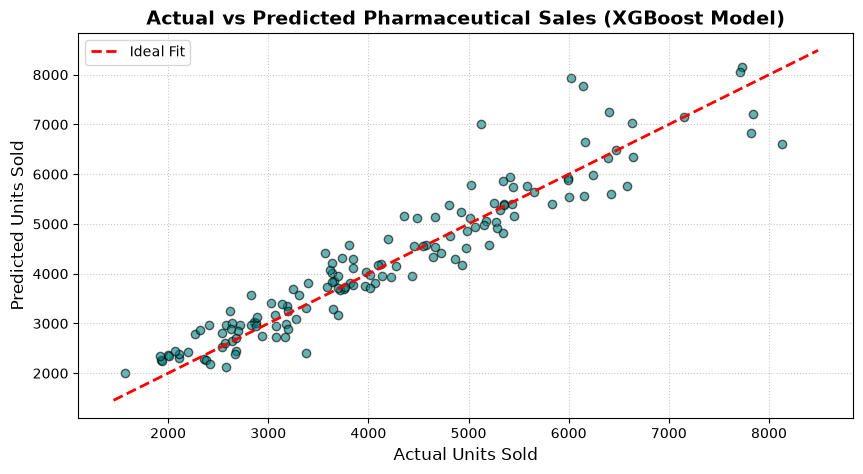

--- INVENTORY OPTIMIZATION DASHBOARD ---


,Date,SKU_ID,Region,Stock_Level,Predicted_Demand,Optimal_Safety_Stock,Reorder_Alert
0,2023-01-31,SKU_AMOX_250,East-Hub,4700,3720.932129,4466.0,False
1,2023-02-28,SKU_AMOX_250,East-Hub,3355,2646.018799,3176.0,False
2,2023-03-31,SKU_AMOX_250,East-Hub,3302,3132.017822,3759.0,True
3,2023-04-30,SKU_AMOX_250,East-Hub,3600,2703.671631,3245.0,False
4,2023-05-31,SKU_AMOX_250,East-Hub,3900,2867.024902,3441.0,False
5,2023-06-30,SKU_AMOX_250,East-Hub,3866,2706.066650,3248.0,False
6,2023-07-31,SKU_AMOX_250,East-Hub,3472,2602.522461,3124.0,False
7,2023-08-31,SKU_AMOX_250,East-Hub,2840,2539.466553,3048.0,True
8,2023-09-30,SKU_AMOX_250,East-Hub,3447,2601.746826,3123.0,False
9,2023-10-31,SKU_AMOX_250,East-Hub,3632,2558.637451,3071.0,False


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize Actual vs Predicted Sales using a scatter plot
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal', edgecolor='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2, label='Ideal Fit')
plt.xlabel('Actual Units Sold', fontsize=12)
plt.ylabel('Predicted Units Sold', fontsize=12)
plt.title('Actual vs Predicted Pharmaceutical Sales (XGBoost Model)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# 2. Inventory Optimization & Reorder Strategy
# Predicting demand for the entire dataset
df['Predicted_Demand'] = model.predict(df[features])

# Maintaining a 20% safety stock buffer over predicted demand
df['Optimal_Safety_Stock'] = np.ceil(df['Predicted_Demand'] * 1.2)

# Flagging whether a reorder is necessary based on current stock levels
df['Reorder_Alert'] = df['Stock_Level'] < df['Optimal_Safety_Stock']

print("--- INVENTORY OPTIMIZATION DASHBOARD ---")
display(df[['Date', 'SKU_ID', 'Region', 'Stock_Level', 'Predicted_Demand', 'Optimal_Safety_Stock', 'Reorder_Alert']].head(10))

In [8]:
%pip install matplotlib seaborn

  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 577.8 kB/s eta 0:00:16
   --- ------------------------------------ 0.8/9.5 MB 793.6 kB/s eta 0:00:11
   ---- ----------------------------------- 1.0/9.5 MB 1.0 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.5 MB 947.7 kB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.5 MB 947.7 kB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.5 MB 947.7 kB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.5 MB 775.9 kB/s eta 0:00:11
   ------- -------------------------------- 1.8/9.5 MB 797.4 kB/s eta 0:00:10
   -------- ------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
